<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Wikipedia and Wikidata](https://github.com/Query-farm/vgi-wikipedia)

Connect Wikipedia articles with Wikidata statements and graph queries from SQL.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-wikipedia/blob/main/notebooks/02_budget_context_without_changing_identity.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-wikipedia/blob/main/notebooks/README.md)


## A context budget changes text length, not article identity

**How much summary text can we keep without losing which article it came from?** Search for Mercury, distinguish the planet and element using explicit article titles and page IDs, reconcile scalar and table summary readers, then apply a local character budget.

**Recorded official public API responses.** Six search hits are an observed search slice, not six interchangeable meanings or an exhaustive topic taxonomy. The two selected articles retain their canonical URLs. Wikipedia text is CC BY-SA; the [recording guide](discovery_recordings/README.md) provides source revisions and contributor attribution. The worker performs the real request/parse work against a strict loopback replay. No model, ranking algorithm or text generation is involved.

### Set the retained-summary budget

`CONTEXT_CHARS` is an integer from 1 to 1000, default **400**, experiment **800**. It limits Unicode characters retained from each already-fetched summary. This is not a token budget, byte count, sentence boundary or estimate of model cost. All six search rows and both full summaries remain fixed. `DATA_MODE` is `recorded` or an explicit `live` public retrieval with no fallback.

In [1]:
CONTEXT_CHARS = 400
DATA_MODE = "recorded"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.38":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.38"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402
from vgi_notebooks.bootstrap import prepare  # noqa: E402

check_runtime()
_companion_directory = prepare("wikipedia")

In [3]:
import json
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from notebook_support import configure, cleanup

state = configure("articles", CONTEXT_CHARS, DATA_MODE)
replay = state["replay"]
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = f"Wikipedia contributors · CC BY-SA · {DATA_MODE.title()} official API responses · two explicit articles"

### Search is candidate discovery

The release command runs in a separate Python3.13 process. Shared setup creates an empty temporary SQL-secret directory, disables persistent secrets and establishes UTC at connection creation. The replay uses the worker's supported MediaWiki endpoint override; live mode resets it to the public English Wikipedia API.

Request one six-row search page and materialize it once. The word count describes article length in this recorded index response; it is not a relevance score or reliability measure. We explicitly choose the planet and element, rather than treating the bare word Mercury as a unique key.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'wiki' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-wikipedia@v0.5.0 vgi-wikipedia-worker');
CREATE TABLE candidates AS SELECT * FROM wiki.main.wiki_search('Mercury',count:=6,max_pages:=1);
CREATE TABLE chosen_titles(title) AS VALUES ('Mercury (planet)'),('Mercury (element)');
SELECT title,pageid,wordcount,url,title IN(SELECT title FROM chosen_titles) AS chosen
FROM candidates ORDER BY wordcount DESC,pageid;

,title,pageid,wordcount,url,chosen
0,Freddie Mercury,42068,17405,https://en.wikipedia.org/wiki/Freddie_Mercury,False
1,Mercury (planet),19694,16192,https://en.wikipedia.org/wiki/Mercury_%28plane...,True
2,Mercury (element),18617142,13586,https://en.wikipedia.org/wiki/Mercury_%28eleme...,True
3,Mercury Records,325909,4260,https://en.wikipedia.org/wiki/Mercury_Records,False
4,Mercury Prize,140995,3833,https://en.wikipedia.org/wiki/Mercury_Prize,False
5,Mercury,19007,974,https://en.wikipedia.org/wiki/Mercury,False


### Carry identity alongside the summary

Retrieve both rich summary rows and page-to-Wikibase mappings. The page ID is scoped to the selected wiki/language; the Wikibase item is a different identifier. Join by page ID after checking titles and URLs. The requested titles are constant function arguments; all results are materialized before capture.

The scalar returns text only, so it must inherit identity from its input row. We verify exact equality with the richer table reader before clipping that text locally. Do not recover identity from the clipped words.

In [5]:
%%sql
CREATE TABLE summaries AS
 SELECT * FROM wiki.main.wiki_page_summary('Mercury (planet)')
 UNION ALL SELECT * FROM wiki.main.wiki_page_summary('Mercury (element)');
CREATE TABLE identities AS
 SELECT * FROM wiki.main.wiki_entity('Mercury (planet)',cache_seconds:=0)
 UNION ALL SELECT * FROM wiki.main.wiki_entity('Mercury (element)',cache_seconds:=0);
CREATE TABLE scalar_text AS SELECT title,wiki.main.wiki_page(title,'en') AS extract FROM chosen_titles;
CREATE TABLE context AS
 SELECT s.title,s.pageid,i.entity_id,s.url,length(s.extract) AS full_chars,
        left(t.extract,{{CONTEXT_CHARS}}) AS retained_extract,
        length(left(t.extract,{{CONTEXT_CHARS}})) AS retained_chars,
        s.extract=t.extract AS readers_agree,i.title=s.title AND i.url=s.url AS identity_agrees
 FROM summaries s JOIN identities i USING(pageid) JOIN scalar_text t ON s.title=t.title;
SELECT title,pageid,entity_id,url,full_chars,retained_chars,readers_agree,identity_agrees FROM context ORDER BY pageid;

,title,pageid,entity_id,url,full_chars,retained_chars,readers_agree,identity_agrees
0,Mercury (planet),19694,Q308,https://en.wikipedia.org/wiki/Mercury_(planet),754,400,True,True
1,Mercury (element),18617142,Q925,https://en.wikipedia.org/wiki/Mercury_(element),398,398,True,True


### Separate search breadth from the selected context

The upper-level search includes several meanings of Mercury. The highlighted two articles are an explicit analytical choice; article length did not select them. Only their summaries enter the character-budget comparison.

In [6]:
%%sql search_frame <<
SELECT title,pageid,wordcount,title IN(SELECT title FROM chosen_titles) AS chosen FROM candidates ORDER BY wordcount DESC,pageid;

,title,pageid,wordcount,chosen
0,Freddie Mercury,42068,17405,False
1,Mercury (planet),19694,16192,True
2,Mercury (element),18617142,13586,True
3,Mercury Records,325909,4260,False
4,Mercury Prize,140995,3833,False
5,Mercury,19007,974,False


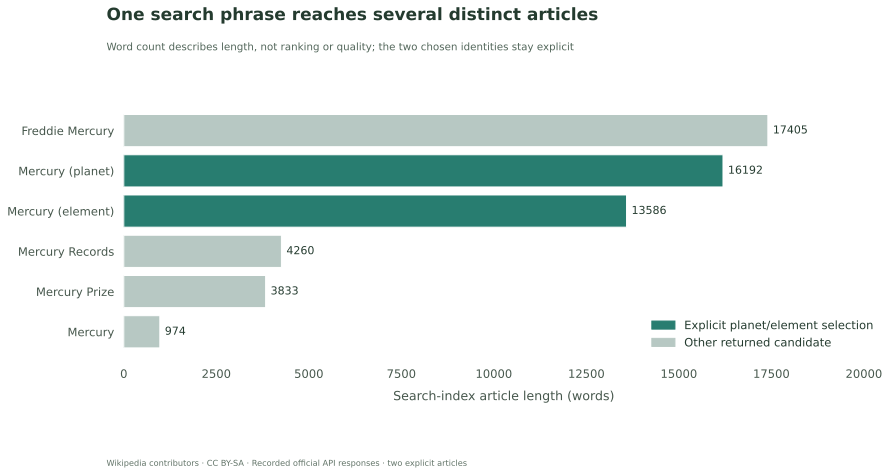

The fixed search slice contains **6 distinct article rows**. We keep the planet and element as separate identities; the other rows are still visible as candidates.

In [7]:
display(search_frame)
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(search_frame))
ax.barh(
    y, search_frame.wordcount, color=["#287D70" if x else "#b7c8c3" for x in search_frame.chosen]
)
ax.set_yticks(y, search_frame.title)
ax.invert_yaxis()
ax.set_xlabel("Search-index article length (words)")
ax.bar_label(ax.containers[0], padding=5)
ax.set_xlim(0, search_frame.wordcount.max() * 1.18)
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="#287D70", label="Explicit planet/element selection"),
        plt.Rectangle((0, 0), 1, 1, color="#b7c8c3", label="Other returned candidate"),
    ],
    loc="lower right",
    frameon=False,
)
finish(
    fig,
    "One search phrase reaches several distinct articles",
    "Word count describes length, not ranking or quality; the two chosen identities stay explicit",
    name="search-breadth",
    source=SOURCE,
)
prose(
    f"The fixed search slice contains **{len(search_frame)} distinct article rows**. We keep the planet and element as separate identities; the other rows are still visible as candidates."
)

### Apply the budget after identity reconciliation

Both lengths use the same Unicode character unit. Clipping preserves the prefix exactly and never overwrites the full source text. A truncated sentence is possible; this example measures retained length rather than claiming that a prefix is sufficient evidence for any downstream answer.

In [8]:
%%sql context_frame <<
SELECT title,pageid,entity_id,url,full_chars,retained_chars,full_chars-retained_chars AS omitted_chars,
       readers_agree,identity_agrees FROM context ORDER BY pageid;

,title,pageid,entity_id,url,full_chars,retained_chars,omitted_chars,readers_agree,identity_agrees
0,Mercury (planet),19694,Q308,https://en.wikipedia.org/wiki/Mercury_(planet),754,400,354,True,True
1,Mercury (element),18617142,Q925,https://en.wikipedia.org/wiki/Mercury_(element),398,398,0,True,True


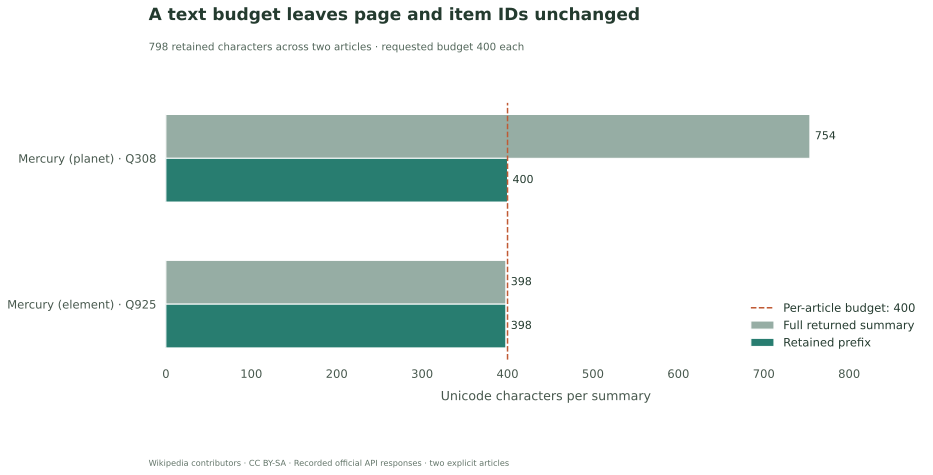

The two readers agree exactly. **354 characters are omitted** across the two retained prefixes. Each row still carries its page ID, item ID and canonical URL; the budget changes no identity mapping.

In [9]:
display(context_frame)
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(context_frame))
width = 0.30
ax.barh(
    y - width / 2,
    context_frame.full_chars,
    height=width,
    color="#96ada4",
    label="Full returned summary",
)
ax.barh(
    y + width / 2,
    context_frame.retained_chars,
    height=width,
    color="#287D70",
    label="Retained prefix",
)
for bars in ax.containers:
    ax.bar_label(bars, padding=5)
ax.set_yticks(y, [f"{r.title} · {r.entity_id}" for r in context_frame.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, max(context_frame.full_chars.max(), CONTEXT_CHARS) * 1.18)
ax.axvline(
    CONTEXT_CHARS, color="#c05a34", linestyle="--", label=f"Per-article budget: {CONTEXT_CHARS}"
)
ax.set_xlabel("Unicode characters per summary")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
finish(
    fig,
    "A text budget leaves page and item IDs unchanged",
    f"{int(context_frame.retained_chars.sum())} retained characters across two articles · requested budget {CONTEXT_CHARS} each",
    name=f"context-{CONTEXT_CHARS}",
    source=SOURCE,
)
prose(
    f"The two readers agree exactly. **{int(context_frame.omitted_chars.sum())} characters are omitted** across the two retained prefixes. Each row still carries its page ID, item ID and canonical URL; the budget changes no identity mapping."
)

### Verify identities, bounded text and request counts

The replay audit checks one search, two page-identity reads and two reads of each summary (one scalar, one table). Captures read local tables and cannot refetch. In live mode these are independent observations; an inconsistent page/title/summary fails the checks rather than being silently merged.

In [10]:
%%sql checks <<
SELECT 'Six unique search pages' AS check_name,count(*)=6 AND count(DISTINCT pageid)=6 AS passed FROM candidates
UNION ALL SELECT 'Two distinct selected page and item IDs',count(*)=2 AND count(DISTINCT pageid)=2 AND count(DISTINCT entity_id)=2 FROM context
UNION ALL SELECT 'Chosen articles occur in the search slice',count(*)=2 FROM chosen_titles JOIN candidates USING(title)
UNION ALL SELECT 'Scalar and rich summaries agree',bool_and(readers_agree) FROM context
UNION ALL SELECT 'Page identity title and URL agree',bool_and(identity_agrees) FROM context
UNION ALL SELECT 'Canonical URLs remain attached',bool_and(starts_with(url,'https://en.wikipedia.org/wiki/')) FROM context
UNION ALL SELECT 'Character budget clips without padding',bool_and(retained_chars=least(full_chars,{{CONTEXT_CHARS}})) FROM context
UNION ALL SELECT 'Retained text is the exact source prefix',bool_and(c.retained_extract=left(s.extract,{{CONTEXT_CHARS}})) FROM context c JOIN summaries s USING(pageid);

In [11]:
display(checks)
assert checks.passed.fillna(False).all()
if replay:
    assert (
        Counter(replay.requests)
        == Counter(
            {
                "article-search": 1,
                "summary-planet": 2,
                "summary-element": 2,
                "identity-planet": 1,
                "identity-element": 1,
            }
        )
        and not replay.rejected
    )
prose(
    "All eight SQL checks passed. The recorded request audit contains seven successful requests and no unknown request."
    if replay
    else "All eight SQL checks passed on independent live public responses."
)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "budget": CONTEXT_CHARS,
            "mode": DATA_MODE,
            "search": search_frame.to_dict("records"),
            "context": context_frame.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": replay.requests if replay else None,
        },
        indent=2,
        default=str,
    )
);

,check_name,passed
0,Six unique search pages,True
1,Two distinct selected page and item IDs,True
2,Chosen articles occur in the search slice,True
3,Scalar and rich summaries agree,True
4,Page identity title and URL agree,True
5,Canonical URLs remain attached,True
6,Character budget clips without padding,True
7,Retained text is the exact source prefix,True


All eight SQL checks passed. The recorded request audit contains seven successful requests and no unknown request.

### Experiment: retain up to 800 characters

Change **CONTEXT_CHARS from 400 to 800** in a separate recorded-mode run. Predict that the retained-prefix bars can grow only up to their returned full lengths. Search rows, page IDs, item IDs, canonical URLs and reader agreement must stay fixed. The search chart stays identical. This is a controlled text-budget experiment, not a new retrieval or a change in article relevance.

Optional `DATA_MODE="live"` performs a separate public read with no fallback. Content can change, so a live result is not the same controlled experiment.

In [12]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
cleanup(state)

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-wikipedia](https://github.com/Query-farm/vgi-wikipedia)